# feecbench — FEEC-native acoustic benchmark: end-to-end reference

A FEEC-native PDE benchmark: an oracle producing verified acoustic-wave reference
solutions across geometry, topology, and resolution; a typed, self-describing format;
a PyTorch loader; and a structure-aware evaluator. The oracle is a placeholder behind
a fixed interface for a later FEEC/MFEM solver.

---
### End-user surface (three calls)

The benchmark is consumed through three entry points. A model author needs nothing
beyond these.

```python
from feecbench import FEECDataset, collate_feec, evaluate_profile

# 1. Load a typed dataset: select split (normalize=None -> raw fields; ⋆-weighted "zscore"/"rms" optional, from train-split stats).
ds = FEECDataset("pilot_data", split="train", normalize=None)

# 2. Batch variable-size meshes (block-diagonal disjoint union); move to device.
batch = collate_feec([ds[i] for i in idxs]).to("cuda")

# 3. Score predictions against a sample: returns a structured metric profile.
profile = evaluate_profile(model_predictions, sample)
```

**Install.** `pip install -e feecbench` (requires `gmsh`, `numpy`, `scipy`, `h5py`,
`torch`, `matplotlib`). Meshing uses the gmsh OpenCASCADE kernel; boundary vertices
lie on the exact CAD curves.

**Contents.**
1. Generate one configuration at three resolutions
2. Sample contents (mesh, typed fields, operators, params, ids, topology, solver)
3. Save and reload, lossless
4. PyTorch loader
5. Filtering, batching, device transfer, cross-resolution access
6. Evaluator: perturbation test
7. Oracle verification: conservation and convergence
8. Sample and metadata schema
9. Pilot corpus: OOD splits and cost estimate
10. Possible extensions

Blockquoted **extension hooks** mark where future features are plugged in. Section 10 summarizes them. These are not implemented here.

In [1]:
from __future__ import annotations

import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

# Locate the repository root (this notebook resides in notebooks/; the package is a
# sibling directory named "feecbench").
ROOT = Path.cwd()
if not (ROOT / "feecbench").exists() and (ROOT.parent / "feecbench").exists():
    ROOT = ROOT.parent
PKG_SRC = ROOT / "feecbench" / "src"
if PKG_SRC.exists():
    sys.path.insert(0, str(PKG_SRC))

import feecbench as fb
from feecbench import (
    FEECDataset,
    ToyAcousticOracle,
    collate_feec,
    evaluate_profile,
    harmonic_basis,
    load_sample,
    save_sample,
    write_index,
)
from feecbench.operators import norm_star
from feecbench.sampler import sample_configs
from feecbench.viz import plot_0cochain, plot_1cochain, plot_mesh

WORK = Path(tempfile.mkdtemp(prefix="feecbench_demo_"))
print(f"feecbench {getattr(fb, '__version__', '0.1.0')}  |  scratch: {WORK}")

feecbench 0.1.0  |  scratch: /tmp/feecbench_demo_nti6siia


## 1. Generate one acoustic configuration at coarse, medium, and fine resolutions

A **configuration** fixes the physics of one problem: geometry family and parameters,
coefficient field, source, initial condition, and boundary condition. It is drawn
reproducibly from `(family, seed, index)`. The oracle discretizes a configuration at
a requested resolution level, yielding one `FEECSample` per level. The three nested
levels share a `config_id`; each carries a distinct `sample_id`.

The governing system, first-order acoustic wave with pressure $p \in C^0$ and
velocity $u \in C^1$:

$$\partial_t p = c^2\,\delta_1 u = c^2\,\star_0^{-1} d_0^\top \star_1 u,
  \qquad \partial_t u = -\,d_0\,p.$$

In [2]:
config = sample_configs("annulus", n=1, seed=7, h_coarse=0.11)[0]
config.update(T=0.6, n_snapshots=7)

oracle = ToyAcousticOracle()
levels = ("coarse", "medium", "fine")
samples = {lvl: oracle.generate(config, lvl) for lvl in levels}

print(f"config_id: {config['config_id']}")
print(f"{'level':8s}{'sample_id':44s}{'n0':>7s}{'n1':>8s}{'n2':>8s}{'beta1':>7s}")
for lvl in levels:
    s = samples[lvl]
    print(f"{lvl:8s}{s.ids.sample_id:44s}"
          f"{len(s.mesh.points):7d}{len(s.mesh.edges):8d}{len(s.mesh.tris):8d}"
          f"{s.topology.betti1:7d}")

config_id: acoustic-annulus-s7-000
level   sample_id                                        n0      n1      n2  beta1
coarse  acoustic-annulus-s7-000-coarse                  329     905     576      1
medium  acoustic-annulus-s7-000-medium                 1234    3538    2304      1
fine    acoustic-annulus-s7-000-fine                   4772   13988    9216      1


> **Extension hook — PDE families and geometries.** The acoustic system is the pilot.
> The four families fixed for the benchmark are diffusion, acoustic wave,
> transient (mixed) Darcy, and incompressible Navier–Stokes, ordered by shared
> conservation/constitutive structure (Maxwell is deferred as a distinct family). Each
> enters through a new `Oracle` implementation and a `register_energy(pde)` entry; the
> field set and form degrees per family are specified in the benchmark design document.
> Geometry families extend to channels, branches, and curved surfaces (sphere, torus)
> through additional `mesh` generators; the schema is unchanged.

## 2. Store mesh, typed fields, sparse operators, parameters, boundary information, and solver metadata

Each `FEECSample` is composed of seven blocks. Every field retains its form degree,
role, and units; every operator is stored as a typed sparse matrix. Derived operators
(codifferential, Hodge Laplacians) are not stored — they are reconstructible from
$d_k$ and $\star_k$.

In [3]:
s = samples["coarse"]
print(s.summary())

FEECSample acoustic-annulus-s7-000-coarse  (config acoustic-annulus-s7-000, coarse, nested)
  mesh: n0=329 n1=905 n2=576   beta=(1,1)  boundary components=2
  orientation: edges_low_to_high; tris_ccw; d_k in R^{n_{k+1} x n_k}
  fields:
    p        degree=0 role=target      shape=(7, 329) units=Pa
    u        degree=1 role=target      shape=(7, 905) units=m^2/s
    p0       degree=0 role=input       shape=(329,) units=Pa
    u0       degree=1 role=input       shape=(905,) units=m^2/s
    c2       degree=2 role=coefficient shape=(576,) units=m^2/s^2
  operators:
    d0     shape=(905, 329) nnz=1810 dtype=int8 type=-
    d1     shape=(576, 905) nnz=1728 dtype=int8 type=-
    star0  shape=(329, 329) nnz=329 dtype=float64 type=lumped_P1
    star1  shape=(905, 905) nnz=4361 dtype=float64 type=whitney_galerkin
    star2  shape=(576, 576) nnz=576 dtype=float64 type=diagonal_area
  solver: ToyAcousticOracle v0.1.0  dt=2.500e-02 cfl=0.5  seed=7  energy_drift=3.73e-16


The discrete de Rham structure is exact and verifiable from the stored operators.

In [4]:
d0, d1 = s.operators["d0"], s.operators["d1"]
star0, star1, star2 = s.operators["star0"], s.operators["star1"], s.operators["star2"]

print(f"d1 @ d0 (max abs entry)          : {abs(d1 @ d0).max()}    [d∘d = 0, exact]")
print(f"boundary vertices / edges         : {int(s.mesh.boundary_vertices.sum())}"
      f" / {int(s.mesh.boundary_edges.sum())}   (2 components: outer + hole)")
print(f"mesh generator / min angle        : {s.mesh.source.get('generator')}"
      f" (gmsh {s.mesh.source.get('gmsh_version', '-')}) / {s.mesh.quality['min_angle_deg']:.1f} deg")
print(f"solver metadata                   : dt={s.solver_meta.dt:.4e},"
      f" seed={s.solver_meta.seed}, energy_drift={s.solver_meta.energy_drift_rel:.2e},"
      f" bc={s.solver_meta.bc_type}")

d1 @ d0 (max abs entry)          : 0    [d∘d = 0, exact]
boundary vertices / edges         : 82 / 82   (2 components: outer + hole)
mesh generator / min angle        : gmsh (gmsh 4.15.2) / 37.5 deg
solver metadata                   : dt=2.5000e-02, seed=7, energy_drift=3.73e-16, bc=sound_hard


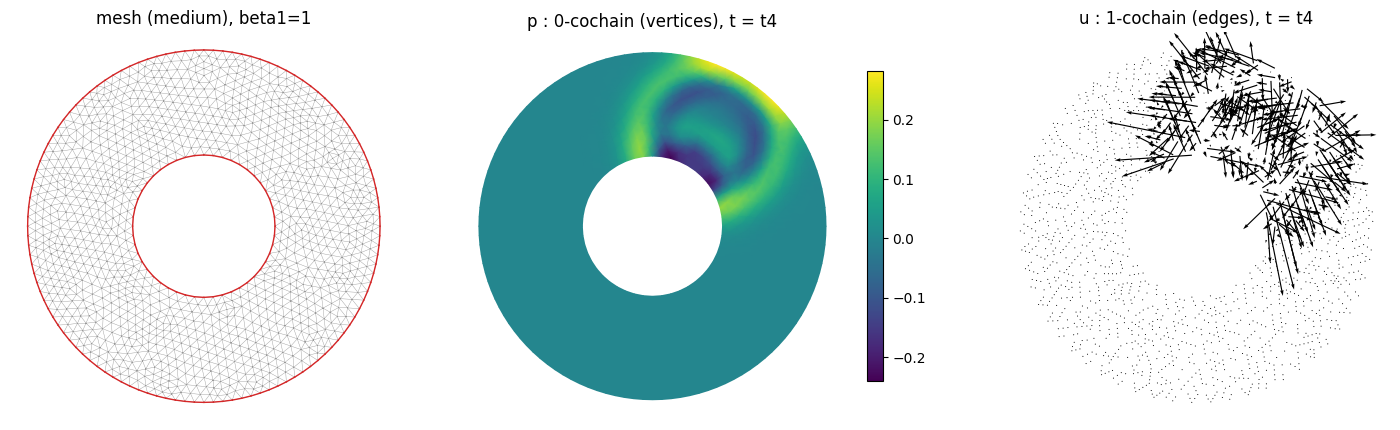

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
plot_mesh(samples["medium"], ax=axes[0])
axes[0].set_title(f"mesh (medium), beta1={samples['medium'].topology.betti1}")
plot_0cochain(samples["medium"], samples["medium"].fields["p"].data[4], ax=axes[1])
axes[1].set_title("p : 0-cochain (vertices), t = t4")
plot_1cochain(samples["medium"], samples["medium"].fields["u"].data[4], ax=axes[2])
axes[2].set_title("u : 1-cochain (edges), t = t4")
for ax in axes:
    ax.set_aspect("equal")
    ax.axis("off")
fig.tight_layout()
plt.show()

> **Extension hook — MFEM oracle and higher order.** `ToyAcousticOracle` is replaced by
> an MFEM-backed oracle behind the same `Oracle.generate(config, level) -> FEECSample`
> interface: `DiscreteLinearOperator` supplies $d_k$, `BilinearForm` mass integrators
> supply $\star_k$, and the H1/Nédélec/Raviart–Thomas/L2 collections realize the de
> Rham complex. Recorded decisions to honor in the schema:
> the pilot is order 1 with higher order as a second track (fields then carry an
> explicit FE-space and polynomial-order tag, and a DoF-to-cell map); $\star_k$ is
> stored sparse always, never as a diagonal vector; the orientation convention is fixed
> and documented once, identically in generator and evaluator.

## 3. Save and reload without losing sparse structure or type information

One self-describing HDF5 file per sample. Sparse operators are stored
as CSR triplets with degree and star-type attributes; fields carry form degree, role,
and units. Reload is bit-exact.

The round-trip preserves CSR sparsity, integer operator dtypes (so `d1 @ d0 = 0`
stays exactly zero, not fuzzy), and the per-field `(degree, role, units)` tags —
precisely the typing that a grid-tensor format (The Well, PDEBench) discards, since
it stores a raw array with no notion of which de Rham space a field lives in.

In [6]:
data_root = WORK / "one_config"
for sm in samples.values():
    save_sample(sm, data_root)
write_index(data_root)

reloaded = load_sample(data_root / s.ids.config_id / f"{s.ids.sample_id}.h5")
fb.assert_samples_equal(s, reloaded)
print("round-trip: arrays, sparsity (CSR), dtypes, and metadata reproduced bit-exactly.")

import h5py  # noqa: E402
with h5py.File(data_root / s.ids.config_id / f"{s.ids.sample_id}.h5") as f:
    groups = sorted({n.split("/")[0] for n in f.keys()})
print("HDF5 top-level groups:", groups)

round-trip: arrays, sparsity (CSR), dtypes, and metadata reproduced bit-exactly.
HDF5 top-level groups: ['fields', 'ids', 'mesh', 'operators', 'params_json', 'solver_meta', 'topology']


## 4. Build a minimal PyTorch loader over local HDF5 storage

`FEECDataset` is a `torch.utils.data.Dataset` over an HDF5 store. A sample is returned
as a dict of typed tensors, sparse operators, boundary masks, and identity metadata.
Optional read-time normalization applies precomputed ⋆-weighted statistics.

In [7]:
ds = FEECDataset(data_root)
item = ds[0]
print(f"len(dataset) = {len(ds)}")
print("item keys   :", list(item.keys()))
print("fields      :", {k: tuple(v.shape) for k, v in item["fields"].items()})
print("operators   :", {k: tuple(v.shape) for k, v in item["operators"].items()})

len(dataset) = 3
item keys   : ['fields', 'field_meta', 'operators', 'n_cells', 'boundary_vertices', 'boundary_edges', 'config_id', 'sample_id', 'resolution_level', 'split', 'params', 'normalized']
fields      : {'c2': (576,), 'p': (7, 329), 'p0': (329,), 'u': (7, 905), 'u0': (905,)}
operators   : {'d0': (905, 329), 'd1': (576, 905), 'star0': (329, 329), 'star1': (905, 905), 'star2': (576, 576)}


## 5. Filtering, batching, device transfer, visualization, and cross-resolution access

The loader implements the API surface required for model evaluation: metadata
filtering; disjoint-union batching of variable-size meshes with per-degree
`batch_index`; device transfer; and configuration-keyed cross-resolution retrieval.

In [8]:
# Filtering by metadata.
coarse = FEECDataset(data_root, filters={"resolution_level": "coarse"})
one_cfg = FEECDataset(data_root, filters={"config_id": config["config_id"]})
print(f"filter resolution_level=coarse -> {len(coarse)} sample(s)")
print(f"filter config_id={config['config_id']} -> {len(one_cfg)} sample(s)")

# Batching two meshes of different size; block-diagonal operators.
batch = collate_feec([ds[0], ds[2]])   # two meshes of different size
device = "cuda" if torch.cuda.is_available() else "cpu"
batch = batch.to(device)
print(f"batched d0 shape {tuple(batch.operators['d0'].shape)}; "
      f"batch_index (deg 0) groups {torch.unique(batch.batch_index[0]).tolist()}; "
      f"device {batch.fields['p'].device}")

# Cross-resolution access; exactness of the nested prolongation.
by_level = {ds[i]["resolution_level"]: ds[i] for i in range(len(ds))}
sc, sm = samples["coarse"], samples["medium"]
gap = np.abs(sc.mesh.points - sm.mesh.points[sm.ids.prolongation]).max()
print(f"cross-resolution levels present: {sorted(by_level)}")
print(f"nested prolongation exactness (coarse->medium): max vertex gap = {gap:.2e}")

filter resolution_level=coarse -> 1 sample(s)
filter config_id=acoustic-annulus-s7-000 -> 3 sample(s)
batched d0 shape (4443, 1563); batch_index (deg 0) groups [0, 1]; device cpu
cross-resolution levels present: ['coarse', 'fine', 'medium']
nested prolongation exactness (coarse->medium): max vertex gap = 0.00e+00


feecbench/src/feecbench/dataset.py:118: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_csr_tensor(
feecbench/src/feecbench/dataset.py:118: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  return torch.sparse_csr_tensor(


The nesting is visible directly: uniform refinement splits every coarse triangle into
four, so each coarse vertex is retained and each coarse edge (bold) coincides with
edges of the finer level (light). This exact overlap is what makes the prolongation an
index map rather than an interpolation — the structure a fixed-grid corpus cannot
store, and the prerequisite for the cross-resolution evaluation of section 10.

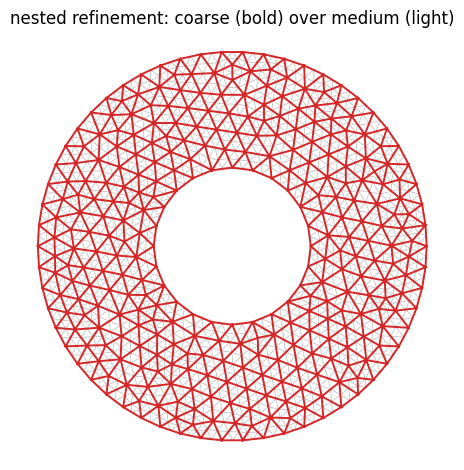

In [9]:
coa_m, med_m = samples["coarse"].mesh, samples["medium"].mesh
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.triplot(med_m.points[:, 0], med_m.points[:, 1], med_m.tris, color="0.72", lw=0.5)
ax.triplot(coa_m.points[:, 0], coa_m.points[:, 1], coa_m.tris, color="C3", lw=1.4)
ax.set_title("nested refinement: coarse (bold) over medium (light)")
ax.set_aspect("equal"); ax.axis("off")
fig.tight_layout()
plt.show()

Batching is a reversible disjoint union: per-sample fields and operators are recovered
bit-exactly from the batched tensors via `batch_index` and per-sample cell counts.

In [10]:
ok = True
for deg, name in ((0, "p"), (1, "u")):
    idx = batch.batch_index[deg]
    for j, orig in enumerate((ds[0], ds[2])):
        cols = (idx == j).nonzero(as_tuple=True)[0]
        ok &= torch.equal(batch.fields[name][..., cols].cpu(), orig["fields"][name])
print(f"batch is losslessly reversible: {ok}")

batch is losslessly reversible: True


> **Extension hook — restriction, commuting transfer, and discretization invariance.**
> Nested levels store the prolongation $P$ (coarse→fine index map). The planned
> additions are the restriction $R$ and the commuting-diagram check $d_k^{(h)} P =
> P\,d_k^{(2h)}$ (equivalently for $R$), which certifies that transfer respects the de
> Rham structure. This is the mechanism behind the discretization-invariance
> evaluation axis — train at one
> resolution, infer at another — and the transferability property
> $R\,T_\theta\,P\,x \approx T_\theta\,x$ that no grid benchmark can measure because
> none stores $P$ and $R$.

## 6. Perturb a solution; verify the evaluator reports the expected errors

The evaluator is validated by injecting perturbations of known structure and
confirming that each activates only the corresponding metric. The metric profile is
dispatched by form degree: a 0-cochain receives accuracy and boundary/interior
errors; a 1-cochain additionally receives closedness ($\lVert d_1 u\rVert$) and the
exact/coexact/harmonic Hodge decomposition of the error. All norms are ⋆-weighted.

In [11]:
target = {"p": s.fields["p"].data[-1].copy(), "u": s.fields["u"].data[-1].copy()}
rng = np.random.default_rng(1)
H = harmonic_basis(s)  # ⋆1-orthonormal harmonic 1-forms; dim = beta1

def with_(**kw):
    pred = {"p": target["p"].copy(), "u": target["u"].copy()}
    pred.update(kw)
    return pred

perturbations = {
    "none (exact)": with_(),
    "noise on p": with_(p=target["p"] + 0.1 * target["p"].std() * rng.standard_normal(target["p"].shape)),
    "harmonic 1-form on u": with_(u=target["u"] + 0.5 * np.abs(target["u"]).max() * H[:, 0]),
    "boundary perturbation on p": with_(),
}
perturbations["boundary perturbation on p"]["p"][s.mesh.boundary_vertices] += 0.5 * np.abs(target["p"]).max()

def leaf(profile, path):
    node = profile["fields"]
    for key in path.split("."):
        node = node[key]
    return float(node)

columns = [
    ("p rel-L2(⋆)", "p.rel_l2_star"),
    ("p boundary", "p.boundary"),
    ("u rel-L2(⋆)", "u.rel_l2_star"),
    ("u closedness", "u.closedness.pred.rel_opnorm"),
    ("u harmonic err", "u.hodge_error.harmonic"),
]
header = f"{'perturbation':28s}" + "".join(f"{name:>16s}" for name, _ in columns)
print(header)
print("-" * len(header))
for label, pred in perturbations.items():
    prof = evaluate_profile(pred, s, target=target)
    row = "".join(f"{leaf(prof, path):16.2e}" for _, path in columns)
    print(f"{label:28s}{row}")

perturbation                     p rel-L2(⋆)      p boundary     u rel-L2(⋆)    u closedness  u harmonic err
------------------------------------------------------------------------------------------------------------
none (exact)                        0.00e+00        0.00e+00        0.00e+00        1.20e-16        0.00e+00
noise on p                          9.59e-02        6.60e-02        0.00e+00        1.20e-16        0.00e+00
harmonic 1-form on u                0.00e+00        0.00e+00        1.11e-01        1.60e-13        1.11e-01
boundary perturbation on p          7.71e-01        1.53e+00        0.00e+00        1.20e-16        0.00e+00


The exact prediction is null across all metrics. The pressure perturbation activates
only the pressure metrics; the boundary perturbation concentrates on the boundary
term. The harmonic perturbation is invisible to closedness — a harmonic 1-form is
closed — and is isolated exclusively by the harmonic component of the Hodge error, a
failure mode inexpressible without the stored operators.

> **Extension hook — hidden-physics track.** Motivated by the PhysicsX result, the
> oracle retains the full physical description of each
> sample while permitting selective visibility: coefficients and constitutive
> information (the acoustic $c^2$, a diffusivity $\kappa$, a Darcy permeability $K$) are
> stored with a per-field visibility flag, so an inference task can withhold part of the
> input and require its recovery, at progressively increasing difficulty. No such track
> is built here; the data model already separates coefficient fields by `role`, which is
> the sole prerequisite.

## 7. Oracle verification: conservation and convergence

The oracle is verified rather than assumed correct. The leapfrog scheme conserves a
discrete energy to machine precision on every sample. On the unit square, the standing
eigenmode $p(x,y,t)=\cos(\pi x)\cos(\pi y)\cos(\sqrt{2}\pi t)$ provides a closed-form
reference; the ⋆-weighted error decays at the theoretical second order.

energy drift (relative), generated samples:
  acoustic-annulus-s7-000-coarse               3.73e-16
  acoustic-annulus-s7-000-medium               2.55e-16
  acoustic-annulus-s7-000-fine                 5.07e-16

eigenmode convergence (unit square):
  h = 0.1250   rel-L2(⋆) = 2.858e-02
  h = 0.0625   rel-L2(⋆) = 7.040e-03
  h = 0.0312   rel-L2(⋆) = 1.736e-03
  observed orders: 2.02, 2.02   (theoretical: 2)


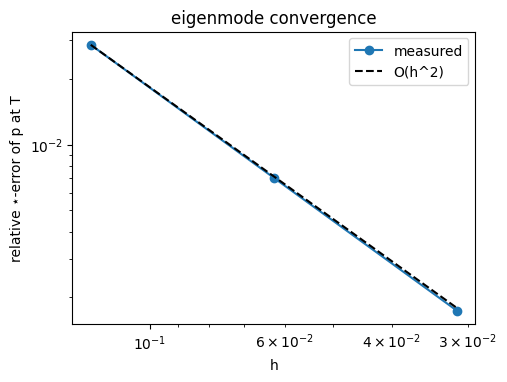

In [12]:
print("energy drift (relative), generated samples:")
for lvl in levels:
    print(f"  {samples[lvl].ids.sample_id:44s} {samples[lvl].solver_meta.energy_drift_rel:.2e}")

conv = {"config_id": "verify-square", "geometry": "unit_square", "geometry_params": {},
        "h_coarse": 1 / 8, "ic": {"type": "eigenmode"}, "c": 1.0,
        "T": 0.5, "n_snapshots": 2, "cfl": 0.25, "seed": 0}
errors, hs = [], []
for i, lvl in enumerate(levels):
    sq = oracle.generate(conv, lvl)
    pts = sq.mesh.points
    t_final = sq.params["t_snapshots"][-1]
    p_exact = (np.cos(np.pi * pts[:, 0]) * np.cos(np.pi * pts[:, 1])
               * np.cos(np.sqrt(2) * np.pi * t_final))
    errors.append(norm_star(sq.fields["p"].data[-1] - p_exact, sq.operators["star0"])
                  / norm_star(p_exact, sq.operators["star0"]))
    hs.append(conv["h_coarse"] / 2 ** i)
rates = [np.log2(errors[i] / errors[i + 1]) for i in range(len(errors) - 1)]

print("\neigenmode convergence (unit square):")
for h, e in zip(hs, errors):
    print(f"  h = {h:.4f}   rel-L2(⋆) = {e:.3e}")
print(f"  observed orders: {', '.join(f'{r:.2f}' for r in rates)}   (theoretical: 2)")

fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.loglog(hs, errors, "o-", label="measured")
ax.loglog(hs, errors[0] * (np.array(hs) / hs[0]) ** 2, "k--", label="O(h^2)")
ax.set_xlabel("h"); ax.set_ylabel("relative ⋆-error of p at T")
ax.invert_xaxis(); ax.legend(); ax.set_title("eigenmode convergence")
plt.show()

> **Extension hook — verification beyond a closed-form solution.** Manufactured
> solutions cover only smooth single-domain cases. For multi-hole domains,
> discontinuous coefficients, and curved surfaces the planned checks are refinement
> (self-convergence) studies, conservation diagnostics, and cross-solver agreement
> against an independent DEC solver. Cross-solver
> comparison is admissible only against a shared exact reference or on a fixed grid
> with a single ground truth, never between two solvers using different finite
> elements.

## 8. Sample and metadata schema

The stored schema realizes the required metadata inventory. Large operators are not
duplicated: the Hodge Laplacians and codifferential are reconstructible from the
stored $d_k$ and $\star_k$.

| block | contents |
|---|---|
| `mesh` | points, edges, tris; orientation convention; boundary vertex/edge masks; quality statistics; mesh source (gmsh / nested-refinement) |
| `fields` | named cochains, each with `form_degree`, `role` ∈ {input, target, coefficient}, `units`; time axis where applicable |
| `operators` | sparse `d0`, `d1` (integer incidence); `star0`, `star1`, `star2` (SPD) with star-type tags |
| `params` | geometry parameters, coefficient `c`, initial condition, source, boundary condition, snapshot times |
| `ids` | `config_id`, `sample_id`, `resolution_level`, `refinement` ∈ {nested, remeshed}, `parent_sample_id`, `prolongation`, `split` |
| `topology` | Betti numbers (analytic and computed), boundary-component count |
| `solver_meta` | solver name/version, `dt`, `cfl`, seed, runtime, convergence flag, energy drift, boundary-condition type |

## 9. Pilot corpus: OOD splits and cost estimate

The pilot corpus spans three geometry families (`unit_square`, `annulus`,
`multi_hole`; $\beta_1 = 0, 1, 2$) at three nested resolutions, with remeshed and
geometry-perturbed variants. Splits are assigned at the **configuration** level so
that no physical configuration appears at two resolutions across the train/test
boundary. The out-of-distribution axes are held-out geometry parameters
(`test_geom_ood`), the entire multi-hole family (`test_topo_ood`), and independent
remeshing (`test_mesh_ood`).

The three families differ in topology, not only shape: $\beta_1$ (the number of
independent 1-cycles, equal to the dimension of the harmonic space the evaluator
measures) is $0$, $1$, $2$. Holding out the entire two-hole family (`test_topo_ood`)
therefore tests generalization to an unseen topology — an axis a fixed-grid benchmark
cannot express.

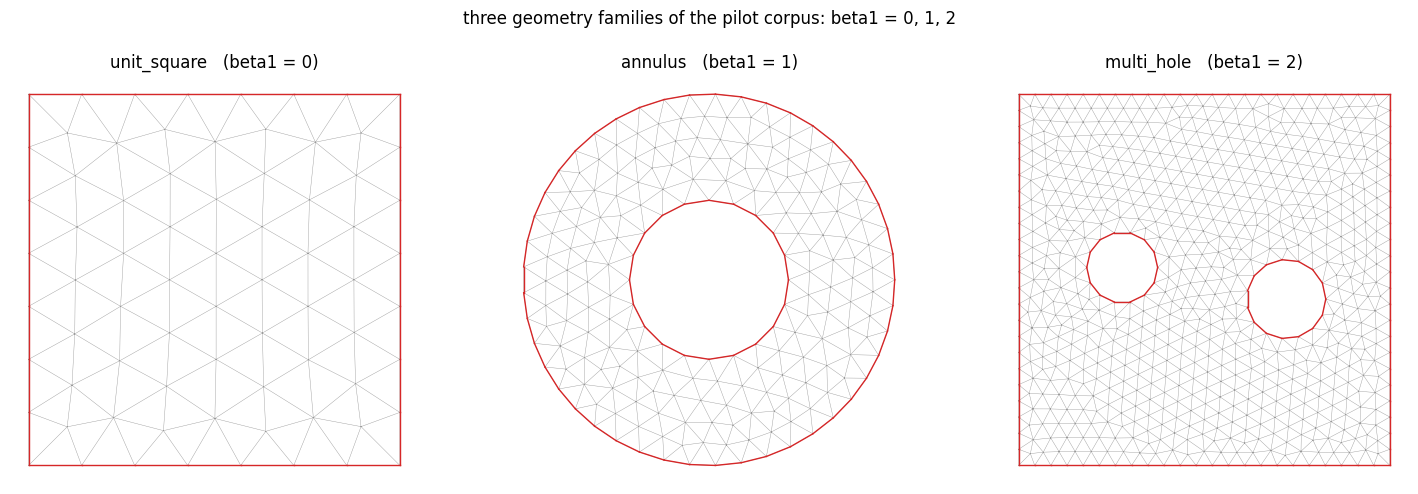

In [13]:
family_specs = [("unit_square", 0, 0.16), ("annulus", 0, 0.14), ("multi_hole", 4, 0.09)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (fam, seed, h) in zip(axes, family_specs):
    fam_cfg = sample_configs(fam, n=1, seed=seed, h_coarse=h)[0]
    fam_sample = oracle.generate(fam_cfg, "coarse")
    plot_mesh(fam_sample, ax=ax)
    ax.set_title(f"{fam}   (beta1 = {fam_sample.topology.betti1})")
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("three geometry families of the pilot corpus: beta1 = 0, 1, 2", y=1.02)
fig.tight_layout()
plt.show()

In [16]:
pilot = ROOT / "feecbench" / "demo" / "pilot_data"
if not pilot.exists():
    subprocess.run([sys.executable, "scripts/build_pilot.py"],
                   cwd=ROOT / "feecbench", check=True)

import json  # noqa: E402
splits = json.loads((pilot / "splits.json").read_text())["split_of_config"]
counts: dict[str, int] = {}
for split_name in splits.values():
    counts[split_name] = counts.get(split_name, 0) + 1
print("configurations per split:")
for name in sorted(counts):
    print(f"  {name:16s} {counts[name]:3d}")

topo = [c for c, v in splits.items() if v == "test_topo_ood"]
print(f"\ntest_topo_ood = the multi_hole family only: "
      f"{all('multi_hole' in c for c in topo)} ({len(topo)} configs)")

cost = (ROOT / "feecbench" / "reports" / "cost_model.md")
if cost.exists():
    print("\ncost model (reports/cost_model.md) — scenario extract:")
    for line in cost.read_text().splitlines():
        if "configs" in line and "|" in line:
            print("  " + line.strip())

== family unit_square ==
  [  1] acoustic-unit_square-s42-000-coarse          split=train          n0=   232 solver=   0.0s
  [  2] acoustic-unit_square-s42-000-medium          split=train          n0=   873 solver=   0.0s
  [  3] acoustic-unit_square-s42-000-fine            split=train          n0=  3385 solver=   0.1s
  [  4] acoustic-unit_square-s42-000-medium-remeshedS42 split=test_mesh_ood  n0=   729 solver=   0.0s
  [  5] acoustic-unit_square-s42-001-coarse          split=train          n0=   232 solver=   0.0s
  [  6] acoustic-unit_square-s42-001-medium          split=train          n0=   873 solver=   0.0s
  [  7] acoustic-unit_square-s42-001-fine            split=train          n0=  3385 solver=   0.1s
  [  8] acoustic-unit_square-s42-001-medium-remeshedS42 split=test_mesh_ood  n0=   729 solver=   0.0s
  [  9] acoustic-unit_square-s42-002-coarse          split=train          n0=   232 solver=   0.0s
  [ 10] acoustic-unit_square-s42-002-medium          split=train          n0= 

## 10. Possible extensions

Tracked in the ongoing Overleaf design document. Each attaches at an existing hook. We should not 
require additional changes to the storage format, loader, or evaluator contract.

| Extension | Integration point (present today) |
|---|---|
| Additional PDE families (diffusion, Darcy, Navier–Stokes) | new `Oracle` implementation + `register_energy(pde)`; fields typed by degree/role |
| FEEC/MFEM oracle | `Oracle.generate(config, level) -> FEECSample`; toy solver is the only replaced component |
| Higher finite-element order | per-field FE-space + polynomial-order tag; DoF-to-cell map; $\star_k$ already stored sparse |
| Restriction $R$ and commuting transfer $d_k P = P d_k$ | prolongation $P$ already stored per nested level |
| Discretization-invariance evaluation | cross-resolution access via shared `config_id` + paired levels |
| Hidden-physics track | coefficient fields separated by `role`; add per-field visibility flag |
| Cross-solver / spectral verification | independent DEC solver behind the same schema; shared exact reference |
| Curved surfaces and 3D | dimension-generic mesh block and per-degree operators |

The sample schema, loader API, and evaluator are model- and solver-independent, so the
benchmark setup should be stable while the oracle, PDE coverage, and evaluation tracks are
extended.